In [20]:
# ========== ML1：数据准备 ==========
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report,
                             roc_curve)
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

# ---------- 特征集 ----------
ml_features = [
    'senna_exposed',
    'gender_male',
    'age_75_84', 'age_85plus',
    'baseline_k', 'baseline_creatinine', 'baseline_egfr',
    'drug_count_no_laxatives',
    'chf', 'ckd', 'dm',
    'diuretic', 'acei_arb', 'digoxin', 'insulin', 'statin', 'anticoagulant',
    'lactulose', 'peg', 'bisacodyl',
    'ppi', 'beta2_agonist', 'corticosteroid',
]

df_ml = df_main.copy()
df_ml['age_75_84']  = (df_ml['age_group'] == '75-84').astype(int)
df_ml['age_85plus'] = (df_ml['age_group'] == '85+').astype(int)

# 只保留特征列 + 结局
df_ml = df_ml[ml_features + ['y']].copy()

# 数值化所有列
for c in ml_features:
    df_ml[c] = pd.to_numeric(df_ml[c], errors='coerce')

# 缺失值用训练集中位数填充（下面 split 后再填，避免泄漏）
print(f'ML 数据集: {len(df_ml)} 行, {len(ml_features)} 特征')
print(f'  低钾率: {df_ml["y"].mean()*100:.2f}%')

# 划分训练/测试集（7:3，分层）
X = df_ml[ml_features]
y = df_ml['y']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# 训练集中位数填充
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_test  = X_test.fillna(train_median)

print(f'  训练集: {len(X_train)}, 测试集: {len(X_test)}')
print(f'  训练集低钾率: {y_train.mean()*100:.2f}%')
print(f'  测试集低钾率: {y_test.mean()*100:.2f}%')

# 标准化（LASSO 用）
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

ML 数据集: 41529 行, 23 特征
  低钾率: 21.07%
  训练集: 29070, 测试集: 12459
  训练集低钾率: 21.07%
  测试集低钾率: 21.08%


scale_pos_weight = 3.745
  Fold 1: AUC = 0.7453
  Fold 2: AUC = 0.7449
  Fold 3: AUC = 0.7501
  Fold 4: AUC = 0.7342
  Fold 5: AUC = 0.7606

5-fold CV AUC: 0.7470 ± 0.0086

=== XGBoost Test Set Performance ===
  AUC       = 0.7439
  Accuracy  = 0.6876
  Precision = 0.3665
  Recall    = 0.6618
  F1        = 0.4718

Classification report:
              precision    recall  f1-score   support

           0     0.8849    0.6945    0.7782      9833
           1     0.3665    0.6618    0.4718      2626

    accuracy                         0.6876     12459
   macro avg     0.6257    0.6782    0.6250     12459
weighted avg     0.7757    0.6876    0.7136     12459


=== SHAP Feature Importance ===
                Feature  Mean |SHAP|
             baseline_k     0.470885
drug_count_no_laxatives     0.468192
                 statin     0.197208
               diuretic     0.165318
               acei_arb     0.144851
                insulin     0.137257
                    ckd     0.119290
    b

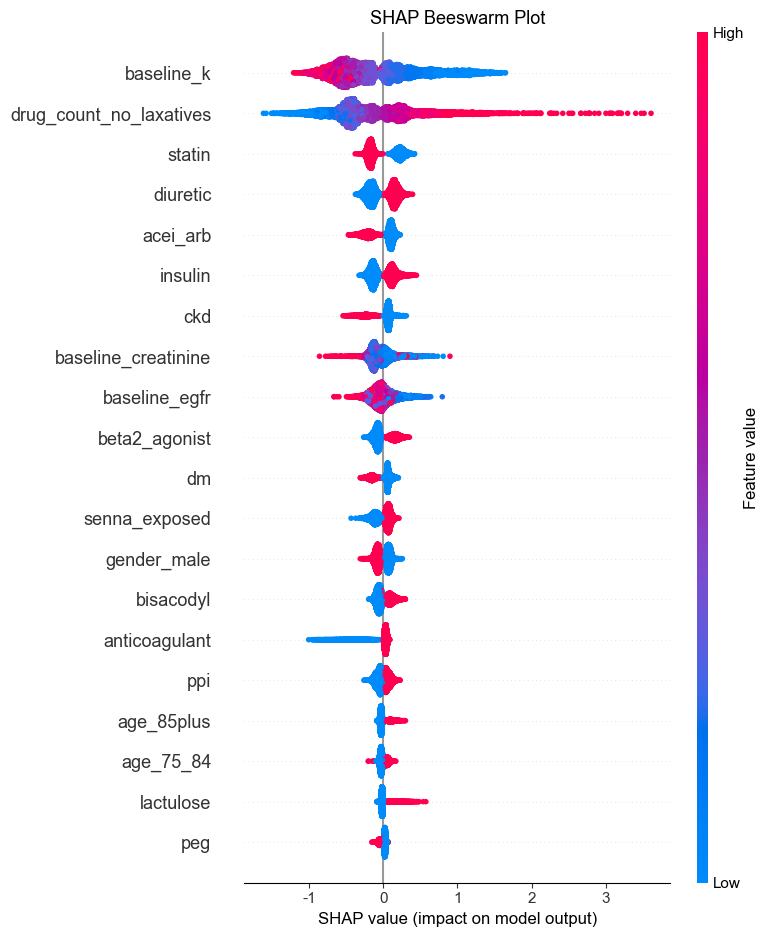

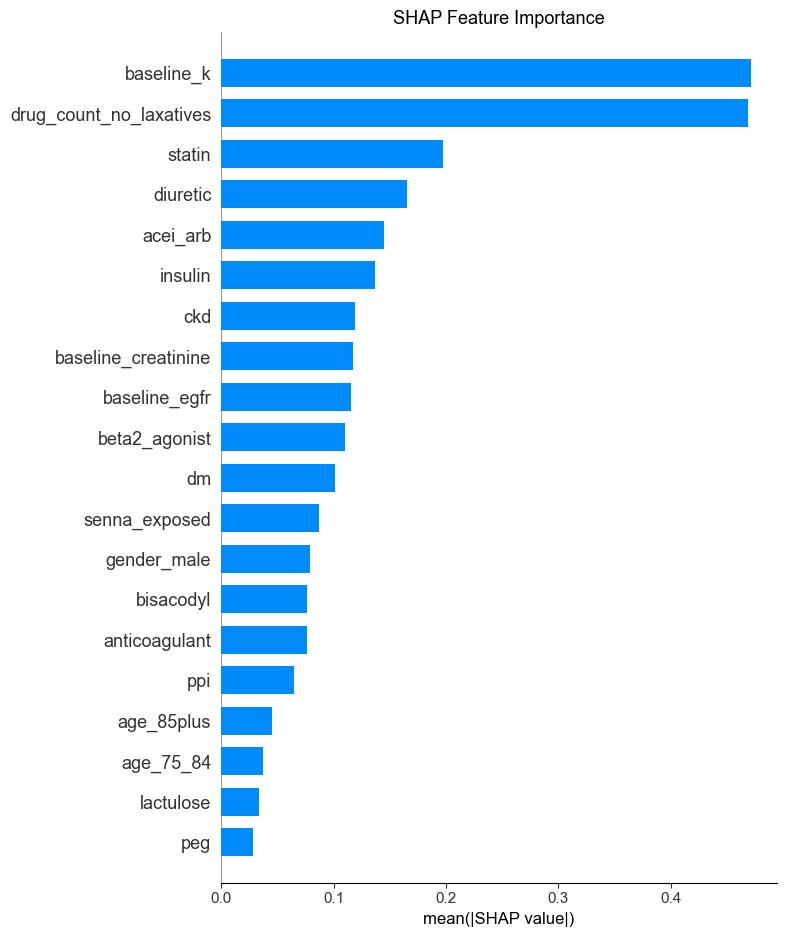


Saved: Figure_SHAP_beeswarm.png, Figure_SHAP_bar.png


In [24]:
# ========== ML2：XGBoost + SHAP（英文字体 Arial）==========
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

# ---------- 全局字体：Arial ----------
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['font.size'] = 11
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
mpl.rcParams['legend.fontsize'] = 10
mpl.rcParams['figure.dpi'] = 100
mpl.rcParams['savefig.dpi'] = 300

# ---------- 依赖 ML1 的变量 ----------
# X_train, X_test, y_train, y_test, ml_features 需已在内存
try:
    X_train, X_test, y_train, y_test, ml_features
except NameError:
    raise RuntimeError('请先跑 ML1')

# ---------- 处理类别不平衡 ----------
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight = {scale_pos:.3f}')

# ---------- XGBoost 模型 ----------
xgb_model = xgb.XGBClassifier(
    max_depth=5,
    learning_rate=0.05,
    n_estimators=300,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    random_state=42,
    eval_metric='logloss',
)

# ---------- 5 折交叉验证 ----------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_aucs = []
for fold, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    xgb_model.fit(X_train.iloc[tr], y_train.iloc[tr])
    pred = xgb_model.predict_proba(X_train.iloc[va])[:, 1]
    auc = roc_auc_score(y_train.iloc[va], pred)
    cv_aucs.append(auc)
    print(f'  Fold {fold}: AUC = {auc:.4f}')
print(f'\n5-fold CV AUC: {np.mean(cv_aucs):.4f} ± {np.std(cv_aucs):.4f}')

# ---------- 全训练集重训 ----------
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

auc_xgb  = roc_auc_score(y_test, y_prob_xgb)
acc_xgb  = accuracy_score(y_test, y_pred_xgb)
prec_xgb = precision_score(y_test, y_pred_xgb)
rec_xgb  = recall_score(y_test, y_pred_xgb)
f1_xgb   = f1_score(y_test, y_pred_xgb)

print(f'\n=== XGBoost Test Set Performance ===')
print(f'  AUC       = {auc_xgb:.4f}')
print(f'  Accuracy  = {acc_xgb:.4f}')
print(f'  Precision = {prec_xgb:.4f}')
print(f'  Recall    = {rec_xgb:.4f}')
print(f'  F1        = {f1_xgb:.4f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred_xgb, digits=4))

# ---------- SHAP ----------
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

mean_shap = pd.DataFrame({
    'Feature': ml_features,
    'Mean |SHAP|': np.abs(shap_values).mean(axis=0),
}).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)

print('\n=== SHAP Feature Importance ===')
print(mean_shap.to_string(index=False))
mean_shap.to_excel('Table_ML_SHAP_importance.xlsx', index=False)

senna_rank = mean_shap[mean_shap['Feature'] == 'senna_exposed'].index[0] + 1
senna_shap = mean_shap.loc[mean_shap['Feature'] == 'senna_exposed',
                            'Mean |SHAP|'].values[0]
print(f'\nsenna_exposed SHAP rank: {senna_rank}')
print(f'senna_exposed mean |SHAP| = {senna_shap:.4f}')

# ---------- SHAP 蜂群图（Arial）----------
with mpl.rc_context({'font.family': 'Arial',
                     'font.sans-serif': ['Arial']}):
    plt.figure(figsize=(9, 7))
    shap.summary_plot(shap_values, X_test,
                      feature_names=ml_features, show=False)
    plt.xlabel('SHAP value (impact on model output)', fontsize=12, family='Arial')
    plt.title('SHAP Beeswarm Plot', fontsize=13, family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_beeswarm.png', dpi=300, bbox_inches='tight')
    plt.show()

# ---------- SHAP 条形图（Arial）----------
with mpl.rc_context({'font.family': 'Arial',
                     'font.sans-serif': ['Arial']}):
    plt.figure(figsize=(8, 7))
    shap.summary_plot(shap_values, X_test,
                      feature_names=ml_features,
                      plot_type='bar', show=False)
    plt.xlabel('mean(|SHAP value|)', fontsize=12, family='Arial')
    plt.title('SHAP Feature Importance', fontsize=13, family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_bar.png', dpi=300, bbox_inches='tight')
    plt.show()

print('\nSaved: Figure_SHAP_beeswarm.png, Figure_SHAP_bar.png')

Top features:
                Feature  Mean |SHAP|
             baseline_k     0.470885
drug_count_no_laxatives     0.468192
                 statin     0.197208
               diuretic     0.165318
               acei_arb     0.144851
                insulin     0.137257


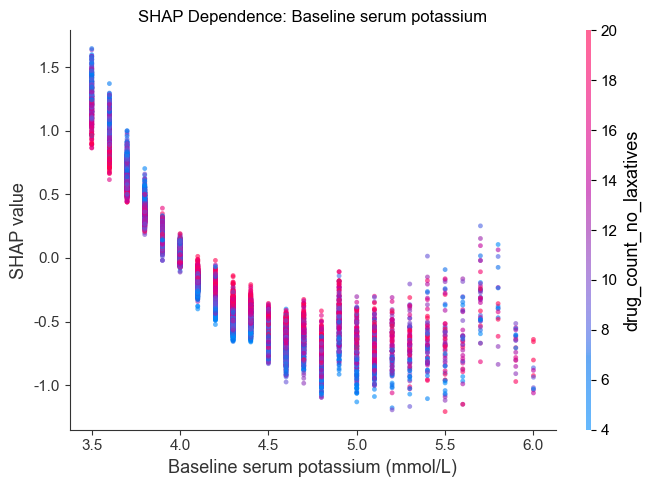

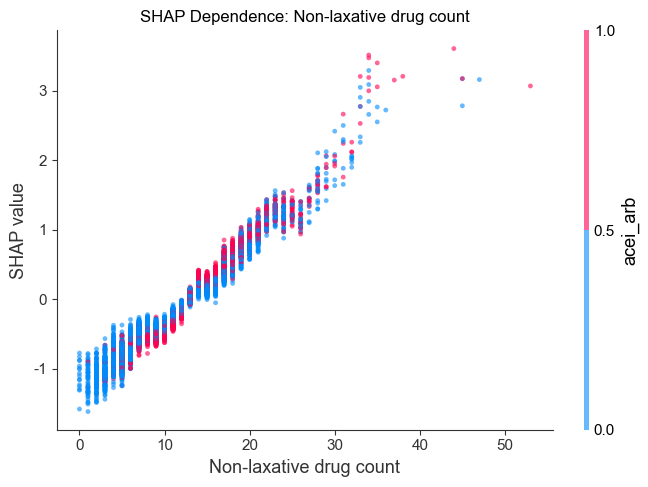

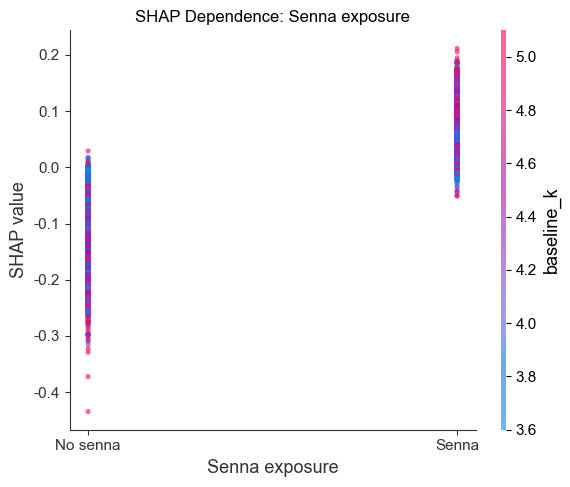

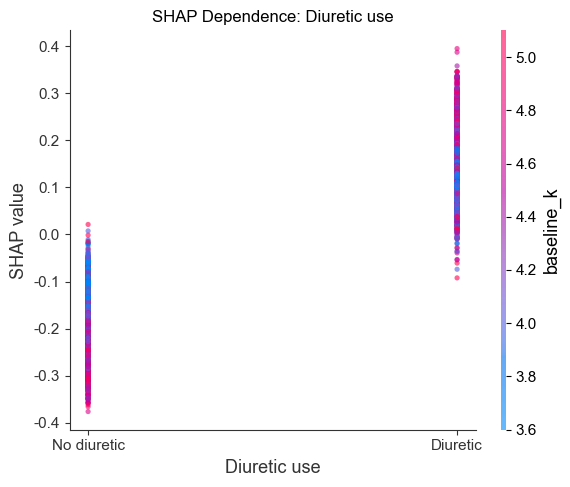

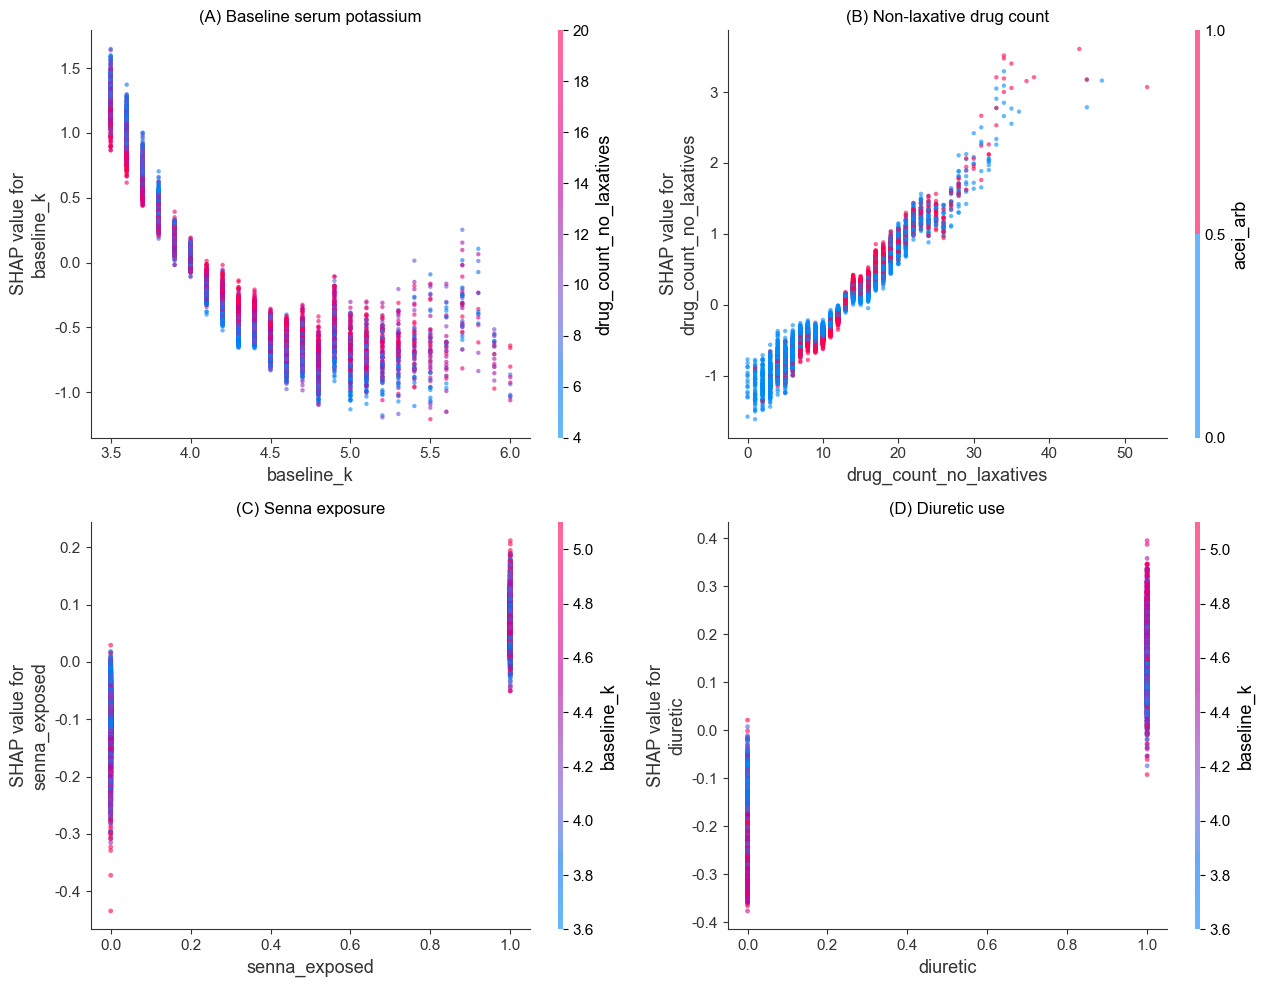


Saved 5 dependence plots.


In [25]:
# ========== ML2b：SHAP 依赖图（英文字体 Arial）==========
import shap
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------- 全局字体：Arial ----------
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['font.size'] = 11
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
mpl.rcParams['legend.fontsize'] = 10
mpl.rcParams['savefig.dpi'] = 300

try:
    shap_values, X_test, ml_features
except NameError:
    raise RuntimeError('请先跑 ML2')

# ---------- 挑选 top 特征（打印参考）----------
mean_shap = pd.DataFrame({
    'Feature': ml_features,
    'Mean |SHAP|': np.abs(shap_values).mean(axis=0),
}).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)
print('Top features:')
print(mean_shap.head(6).to_string(index=False))

# ---------- 图 1：基线血钾 ----------
with mpl.rc_context({'font.family': 'Arial'}):
    fig, ax = plt.subplots(figsize=(7, 5))
    shap.dependence_plot(
        'baseline_k', shap_values, X_test,
        feature_names=ml_features,
        interaction_index='auto',
        show=False, ax=ax,
        dot_size=12, alpha=0.6,
    )
    ax.set_xlabel('Baseline serum potassium (mmol/L)', family='Arial')
    ax.set_ylabel('SHAP value', family='Arial')
    ax.set_title('SHAP Dependence: Baseline serum potassium', family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_dependence_baselineK.png',
                dpi=300, bbox_inches='tight')
    plt.show()

# ---------- 图 2：非泻药合并用药数 ----------
with mpl.rc_context({'font.family': 'Arial'}):
    fig, ax = plt.subplots(figsize=(7, 5))
    shap.dependence_plot(
        'drug_count_no_laxatives', shap_values, X_test,
        feature_names=ml_features,
        interaction_index='auto',
        show=False, ax=ax,
        dot_size=12, alpha=0.6,
    )
    ax.set_xlabel('Non-laxative drug count', family='Arial')
    ax.set_ylabel('SHAP value', family='Arial')
    ax.set_title('SHAP Dependence: Non-laxative drug count', family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_dependence_drugcount.png',
                dpi=300, bbox_inches='tight')
    plt.show()

# ---------- 图 3：senna_exposed ----------
with mpl.rc_context({'font.family': 'Arial'}):
    fig, ax = plt.subplots(figsize=(6, 5))
    shap.dependence_plot(
        'senna_exposed', shap_values, X_test,
        feature_names=ml_features,
        interaction_index='baseline_k',
        show=False, ax=ax,
        dot_size=14, alpha=0.6,
    )
    ax.set_xlabel('Senna exposure', family='Arial')
    ax.set_ylabel('SHAP value', family='Arial')
    ax.set_title('SHAP Dependence: Senna exposure', family='Arial')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No senna', 'Senna'], family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_dependence_senna.png',
                dpi=300, bbox_inches='tight')
    plt.show()

# ---------- 图 4：利尿剂 ----------
with mpl.rc_context({'font.family': 'Arial'}):
    fig, ax = plt.subplots(figsize=(6, 5))
    shap.dependence_plot(
        'diuretic', shap_values, X_test,
        feature_names=ml_features,
        interaction_index='baseline_k',
        show=False, ax=ax,
        dot_size=14, alpha=0.6,
    )
    ax.set_xlabel('Diuretic use', family='Arial')
    ax.set_ylabel('SHAP value', family='Arial')
    ax.set_title('SHAP Dependence: Diuretic use', family='Arial')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No diuretic', 'Diuretic'], family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_dependence_diuretic.png',
                dpi=300, bbox_inches='tight')
    plt.show()

# ---------- 图 5：2x2 组合大图 ----------
with mpl.rc_context({'font.family': 'Arial'}):
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))

    shap.dependence_plot('baseline_k', shap_values, X_test,
                         feature_names=ml_features, interaction_index='auto',
                         show=False, ax=axes[0, 0], dot_size=10, alpha=0.6)
    axes[0, 0].set_title('(A) Baseline serum potassium', family='Arial')

    shap.dependence_plot('drug_count_no_laxatives', shap_values, X_test,
                         feature_names=ml_features, interaction_index='auto',
                         show=False, ax=axes[0, 1], dot_size=10, alpha=0.6)
    axes[0, 1].set_title('(B) Non-laxative drug count', family='Arial')

    shap.dependence_plot('senna_exposed', shap_values, X_test,
                         feature_names=ml_features,
                         interaction_index='baseline_k',
                         show=False, ax=axes[1, 0], dot_size=12, alpha=0.6)
    axes[1, 0].set_title('(C) Senna exposure', family='Arial')

    shap.dependence_plot('diuretic', shap_values, X_test,
                         feature_names=ml_features,
                         interaction_index='baseline_k',
                         show=False, ax=axes[1, 1], dot_size=12, alpha=0.6)
    axes[1, 1].set_title('(D) Diuretic use', family='Arial')

    plt.tight_layout()
    plt.savefig('Figure_SHAP_dependence_panel.png',
                dpi=300, bbox_inches='tight')
    plt.show()

print('\nSaved 5 dependence plots.')

Best C = 0.05

=== LASSO Test Set Performance ===
  AUC       = 0.7286
  Accuracy  = 0.6671
  Precision = 0.3485
  Recall    = 0.6668
  F1        = 0.4578

=== LASSO Standardized Coefficients ===
                Feature  Coefficient
drug_count_no_laxatives     0.555143
             baseline_k    -0.491833
                 statin    -0.236576
               acei_arb    -0.169811
                insulin     0.168129
                    ckd    -0.149536
                     dm    -0.134377
          beta2_agonist     0.132225
               diuretic     0.131205
            gender_male    -0.126571
          anticoagulant     0.124199
    baseline_creatinine     0.118448
          senna_exposed     0.095529
             age_85plus     0.076888
                    ppi     0.075219
              lactulose     0.068610
              age_75_84     0.058568
              bisacodyl     0.048709
                    chf     0.027456
                    peg    -0.026466
                digoxin    

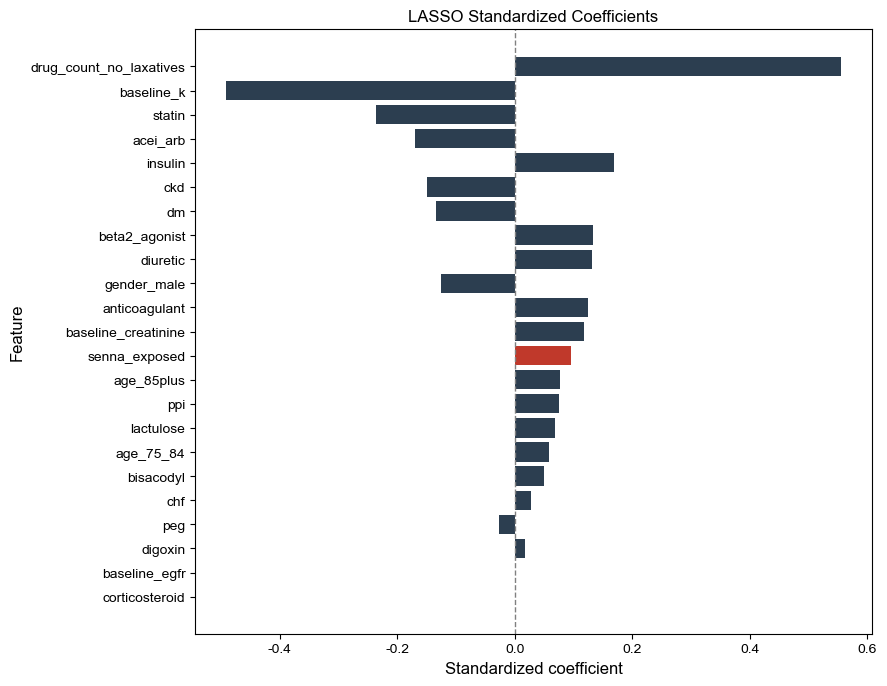


Saved: Figure_LASSO_coefficients.png


In [26]:
# ========== ML3：LASSO 逻辑回归（英文字体 Arial）==========
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)

# ---------- 全局字体：Arial ----------
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['font.size'] = 11
mpl.rcParams['axes.labelsize'] = 12
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
mpl.rcParams['savefig.dpi'] = 300

try:
    X_train_scaled, X_test_scaled, y_train, y_test, ml_features
except NameError:
    raise RuntimeError('请先跑 ML1')

# ---------- 网格搜索 ----------
C_grid = [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]
lasso_base = LogisticRegression(
    penalty='l1', solver='saga', class_weight='balanced',
    max_iter=5000, random_state=42
)
grid = GridSearchCV(lasso_base,
                    param_grid={'C': C_grid},
                    scoring='roc_auc',
                    cv=StratifiedKFold(5, shuffle=True, random_state=42),
                    n_jobs=-1)
grid.fit(X_train_scaled, y_train)
best_C = grid.best_params_['C']
print(f'Best C = {best_C}')

lasso_model = grid.best_estimator_
y_prob_lasso = lasso_model.predict_proba(X_test_scaled)[:, 1]
y_pred_lasso = lasso_model.predict(X_test_scaled)

auc_lasso  = roc_auc_score(y_test, y_prob_lasso)
acc_lasso  = accuracy_score(y_test, y_pred_lasso)
prec_lasso = precision_score(y_test, y_pred_lasso)
rec_lasso  = recall_score(y_test, y_pred_lasso)
f1_lasso   = f1_score(y_test, y_pred_lasso)

print(f'\n=== LASSO Test Set Performance ===')
print(f'  AUC       = {auc_lasso:.4f}')
print(f'  Accuracy  = {acc_lasso:.4f}')
print(f'  Precision = {prec_lasso:.4f}')
print(f'  Recall    = {rec_lasso:.4f}')
print(f'  F1        = {f1_lasso:.4f}')

# ---------- 系数 ----------
coef_df = pd.DataFrame({
    'Feature': ml_features,
    'Coefficient': lasso_model.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False).reset_index(drop=True)
print('\n=== LASSO Standardized Coefficients ===')
print(coef_df.to_string(index=False))
coef_df.to_excel('Table_ML_LASSO_coefficients.xlsx', index=False)

senna_coef = coef_df.loc[coef_df['Feature'] == 'senna_exposed',
                          'Coefficient'].values[0]
print(f'\nsenna_exposed LASSO coefficient = {senna_coef:.4f}')

print(f'\n=== AUC Comparison ===')
print(f'  XGBoost: {auc_xgb:.4f}')
print(f'  LASSO:   {auc_lasso:.4f}')
print(f'  Diff:    {abs(auc_xgb - auc_lasso):.4f}')

# ---------- 系数条形图（Arial）----------
with mpl.rc_context({'font.family': 'Arial'}):
    plt.figure(figsize=(9, 7))
    colors = ['#C0392B' if f == 'senna_exposed' else '#2C3E50'
              for f in coef_df['Feature']]
    plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
    plt.axvline(0, color='gray', linestyle='--', linewidth=1)
    plt.xlabel('Standardized coefficient', family='Arial')
    plt.ylabel('Feature', family='Arial')
    plt.title('LASSO Standardized Coefficients', family='Arial')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('Figure_LASSO_coefficients.png',
                dpi=300, bbox_inches='tight')
    plt.show()

print('\nSaved: Figure_LASSO_coefficients.png')